<a href="https://colab.research.google.com/github/SNMS95/CAD_LAYOUT_PRED/blob/main/notebooks/results.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Object list → room layout → NURBS CAD: results

This notebook summarises the prototype and shows results for the **end-to-end model**: the diffusion model trained with the overlap loss (λ = 1, `runs/diffusion_ovl1/best.pt`).

Every layout below comes **straight from the network**. There is no sampling-time guidance and no post-hoc refinement.

In [1]:
import json, math, os, sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
os.chdir(ROOT)

from cadlayout import CIRCLE, SQUARE, TYPE_NAMES
from cadlayout.data import LayoutDataset, collate
from cadlayout.geometry import layout_violations, to_shapely
from cadlayout.nurbs import pose_to_nurbs
from cadlayout.train import get_device, load_checkpoint
from cadlayout.viz import plot_layout

DEV = get_device()
CKPT = "runs/diffusion_ovl1/best.pt"
model, diff, cfg = load_checkpoint(CKPT, DEV)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"device: {DEV}   checkpoint: {CKPT}   overlap weight λ = {cfg['overlap_weight']}")

device: mps   checkpoint: runs/diffusion_ovl1/best.pt   overlap weight λ = 1.0


## 1. Aim

**Input:** a list of objects of varying length. Each object is a circle (with a radius) or a square (with a side length).
**Output:** a CAD model (NURBS curves) of those objects arranged inside a fixed 1 × 1 square room, such that
- no two objects overlap, and
- every object is fully inside the room.

Many different arrangements are correct for the same list, so the model is **generative**. Each run gives a different valid layout.

## 2. Data

There is no real dataset, so layouts are generated synthetically (`cadlayout/data.py`):
1. **Pick the objects.** Choose N, then for each object a type (circle or square, 50/50) and a size:
   - circle radius ∈ [0.03, 0.15];
   - square side ∈ [0.05, 0.25].

   Object sets covering more than 40% of the room are rejected.
2. **Place them by rejection sampling, largest first.** Draw a random position (and a random angle for squares) and keep it if it overlaps nothing already placed; otherwise try again.

| split | layouts | objects per layout |
|---|---|---|
| train | 50,000 | 2–8 |
| val | 5,000 | 2–8 |
| test | 5,000 | 2–8 |
| **test_ood** | 2,000 | **9–12** (never seen in training) |

train     layouts= 50000  objects/layout: min=2 mean=5.0 max=8  circles=50%
val       layouts=  5000  objects/layout: min=2 mean=5.0 max=8  circles=50%
test      layouts=  5000  objects/layout: min=2 mean=5.0 max=8  circles=50%
test_ood  layouts=  2000  objects/layout: min=9 mean=10.4 max=12  circles=49%


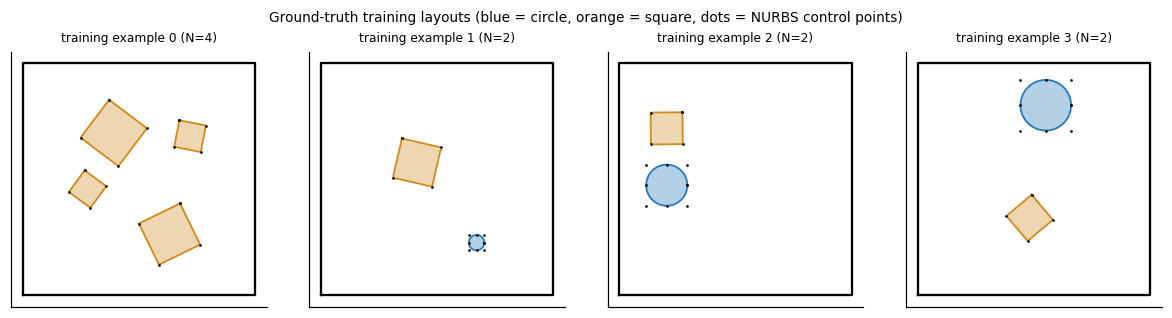

In [2]:
splits = {s: LayoutDataset(f"data/{s}.pt") for s in ["train", "val", "test", "test_ood"]}
for s, ds in splits.items():
    n = ds.mask.sum(1)
    frac_c = (ds.types[ds.mask] == CIRCLE).float().mean()
    print(f"{s:9s} layouts={len(ds):6d}  objects/layout: min={n.min()} mean={n.float().mean():.1f} max={n.max()}  circles={frac_c:.0%}")

def unpack(ds, i, poses=None):
    t, s, p, m = ds[i]
    p = p if poses is None else poses
    return t[m].numpy(), s[m].numpy().astype(float), np.asarray(p)[: int(m.sum())].astype(float)

fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for ax, i in zip(axes, range(4)):
    plot_layout(ax, *unpack(splits["train"], i), title=f"training example {i} (N={int(splits['train'].mask[i].sum())})")
fig.suptitle("Ground-truth training layouts (blue = circle, orange = square, dots = NURBS control points)", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Model input and output

**Key idea:** the network does **not** predict NURBS parameters. A circle's or square's NURBS is fully determined by its size and pose, so the network predicts only the pose, and a fixed decoder (with no learned parameters) builds the exact NURBS.

```
input  (per object):  type (circle/square), size
      │
      ▼   SetGraphDenoiser  — graph transformer over all object pairs (≈1.85M parameters)
      │                       • works for any number of objects
      │                       • output does not depend on the order of the input list
      ▼
output (per object):  pose = (x, y, θ)
      │
      ▼   fixed NURBS decoder: scale a unit template by the size, rotate by θ, move to (x, y)
CAD:  circle = degree-2 rational NURBS, 9 control points
      square = degree-1 NURBS, 5 control points      →  DXF / JSON
```

Inside the network the pose is encoded as `(2x−1, 2y−1, cos 4θ, sin 4θ)`. The factor 4 makes a square at θ and at θ + 90° identical, which they are. Circles have no rotation.

The cell below runs the full chain for one test object list.

INPUT  (object list)                 OUTPUT (predicted pose)            NURBS (decoded)
  #0 square size=0.170    →   x=0.526 y=0.328 θ=  -7.8°   →   degree 1, 5 control points, weights [1.0, 1.0, 1.0]...
  #1 circle size=0.038    →   x=0.442 y=0.579 θ=   0.0°   →   degree 2, 9 control points, weights [1.0, 0.707, 1.0]...
  #2 square size=0.111    →   x=0.098 y=0.325 θ=   5.4°   →   degree 1, 5 control points, weights [1.0, 1.0, 1.0]...
  #3 square size=0.073    →   x=0.086 y=0.097 θ=  37.7°   →   degree 1, 5 control points, weights [1.0, 1.0, 1.0]...
  #4 circle size=0.091    →   x=0.651 y=0.819 θ=   0.0°   →   degree 2, 9 control points, weights [1.0, 0.707, 1.0]...


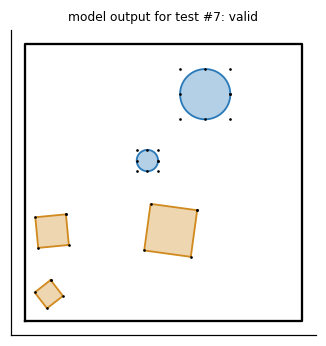

In [3]:
ds = splits["test"]
# first test layout with 5 objects containing both circles and squares
i = next(j for j in range(len(ds)) if int(ds.mask[j].sum()) == 5 and len(set(ds.types[j][ds.mask[j]].tolist())) == 2)
b = {k: v.to(DEV) for k, v in collate([ds[i]]).items()}
g = torch.Generator(device=DEV).manual_seed(0)
poses = diff.sample(model, b["types"], b["sizes"], b["mask"], steps=50, guidance=0.0, generator=g)[0].cpu().numpy()
types, sizes, poses = unpack(ds, i, poses)

print("INPUT  (object list)                 OUTPUT (predicted pose)            NURBS (decoded)")
for k, (t, s, p) in enumerate(zip(types, sizes, poses)):
    crv = pose_to_nurbs(t, s, *p)
    print(f"  #{k} {TYPE_NAMES[int(t)]:6s} size={s:.3f}    →   x={p[0]:.3f} y={p[1]:.3f} θ={math.degrees(p[2]):6.1f}°   →   "
          f"degree {crv.degree}, {len(crv.ctrl)} control points, weights {np.round(crv.weights, 3).tolist()[:3]}...")

fig, ax = plt.subplots(figsize=(3.6, 3.6))
v = layout_violations(types, sizes, poses)
plot_layout(ax, types, sizes, poses, title=f"model output for test #{i}: {'valid' if v['valid'] else 'INVALID'}")
plt.show()

## 4. Training

**Diffusion training.** Take a valid layout and add a random amount of noise to every object's pose. The network learns to predict that noise (the *fit loss*: mean squared error between predicted and true noise). To generate, start from pure noise and remove it step by step (50 DDIM steps).

**Overlap loss (what makes it end-to-end).** From the predicted noise we can compute the network's current guess of the clean layout, x̂₀. A differentiable penalty P scores that guess for overlaps and wall crossings. The penalty is built from points on each shape's NURBS outline tested against the other shapes' signed distance functions, plus an inscribed-circle term. Training minimises

$$\mathcal{L} = \underbrace{\lVert \hat\varepsilon - \varepsilon \rVert^2}_{\text{fit loss}} \;+\; \lambda \cdot \underbrace{\bar\alpha_t \, P(\hat x_0)}_{\text{overlap loss}}, \qquad \lambda = 1$$

The weight ᾱ_t is ≈ 1 at low noise and ≈ 0 at high noise, so overlaps are only penalised when the guess is sharp enough for them to mean something.

Settings: 100 epochs, batch size 256, AdamW (learning rate 2·10⁻⁴, one-cycle schedule), an exponential moving average (EMA) of the weights, 500 diffusion timesteps. About 30 minutes on an Apple-silicon GPU (MPS).

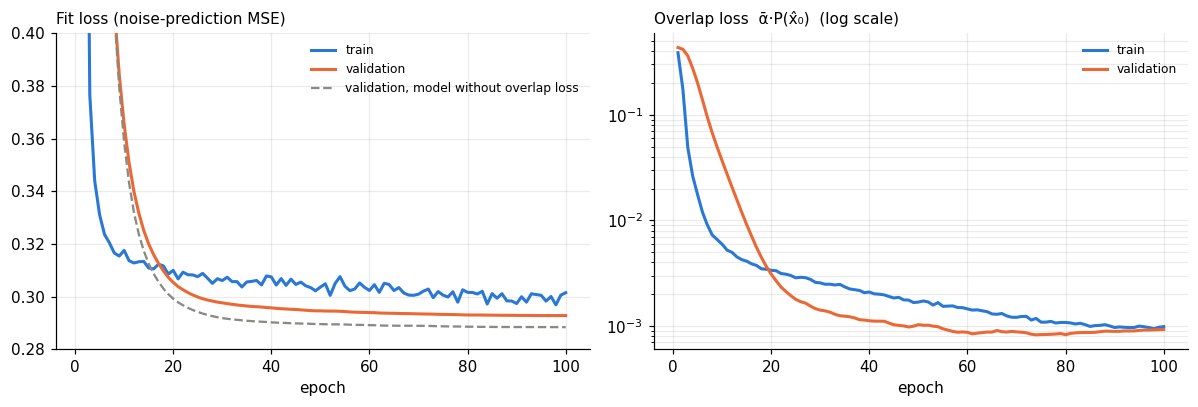

best epoch 96: val fit loss 0.2928, val overlap loss 0.00092
model without overlap loss: best val fit loss 0.2884


In [4]:
hist = torch.load("runs/diffusion_ovl1/last.pt", map_location="cpu")["history"]
base = torch.load("runs/diffusion/last.pt", map_location="cpu")["history"]
ep = [h["epoch"] for h in hist]
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(ep, [h["train_fit"] for h in hist], color=BLUE, lw=2, label="train")
a1.plot(ep, [h["val"] for h in hist], color=ORANGE, lw=2, label="validation")
a1.plot([h["epoch"] for h in base], [h["val"] for h in base], color=GRAY, lw=1.5, ls="--", label="validation, model without overlap loss")
a1.set_ylim(0.28, 0.40); a1.set_title("Fit loss (noise-prediction MSE)", fontsize=10, loc="left")
a1.set_xlabel("epoch"); a1.grid(alpha=0.25); a1.legend(frameon=False, fontsize=8)

a2.plot(ep, [h["train_overlap"] for h in hist], color=BLUE, lw=2, label="train")
a2.plot(ep, [h["val_overlap"] for h in hist], color=ORANGE, lw=2, label="validation")
a2.set_yscale("log"); a2.set_title("Overlap loss  ᾱ·P(x̂₀)  (log scale)", fontsize=10, loc="left")
a2.set_xlabel("epoch"); a2.grid(alpha=0.25, which="both"); a2.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

best = min(hist, key=lambda h: h["val"])
print(f"best epoch {best['epoch']}: val fit loss {best['val']:.4f}, val overlap loss {best['val_overlap']:.5f}")
print(f"model without overlap loss: best val fit loss {min(h['val'] for h in base):.4f}")

How to read the curves:
- **Validation is below training.** Validation uses the EMA (averaged) weights and a fixed noise draw, which gives smoother, slightly lower numbers. This does not indicate a problem.
- **The fit loss settles at ≈ 0.29.** It cannot reach 0, because many layouts are compatible with the same noisy input.
- **The overlap-loss model ends almost level with the one without it** (0.293 vs 0.288). The constraint costs very little denoising accuracy.
- **The overlap loss falls by about 400×** (from ≈ 0.39 to ≈ 0.001). The network has learned to output non-overlapping layouts by itself.

## 5. Results: end-to-end (network only, no guidance or refinement)

The headline numbers come from the full evaluation on 1,000 layouts per split (`outputs/ovl_eval_*/metrics.json`). A layout counts as **valid** if shapely (an independent geometry library) finds no overlap and nothing outside the room.

In [5]:
rows = []
for split, label in [("test", "test (N = 2–8)"), ("test_ood", "OOD (N = 9–12)")]:
    m = json.load(open(f"outputs/ovl_eval_{split}/metrics.json"))
    for key, name in [("diffusion_raw", "diffusion, no overlap loss"), ("diff_ovl1_raw", "diffusion + overlap loss (λ=1)")]:
        r = m[key]
        rows.append((label, name, r["valid_pct"], r["overlap_pairs_mean"], m["diversity"][key]))
print(f"{'split':16s} {'model':32s} {'valid %':>8s} {'overlapping pairs/layout':>25s} {'diversity':>10s}")
for r in rows:
    print(f"{r[0]:16s} {r[1]:32s} {r[2]:8.1f} {r[3]:25.3f} {r[4]:10.3f}")

split            model                             valid %  overlapping pairs/layout  diversity
test (N = 2–8)   diffusion, no overlap loss           75.8                     0.281      0.433
test (N = 2–8)   diffusion + overlap loss (λ=1)       93.6                     0.015      0.454
OOD (N = 9–12)   diffusion, no overlap loss           17.5                     1.699      0.453
OOD (N = 9–12)   diffusion + overlap loss (λ=1)       60.9                     0.178      0.484


In [6]:
def sample_and_plot(split, idx, title, seed=0):
    ds = splits[split]
    b = {k: v.to(DEV) for k, v in collate([ds[i] for i in idx]).items()}
    g = torch.Generator(device=DEV).manual_seed(seed)
    P = diff.sample(model, b["types"], b["sizes"], b["mask"], steps=50, guidance=0.0, generator=g).cpu().numpy()
    fig, axes = plt.subplots(2, 4, figsize=(11, 6.4))
    n_valid = 0
    for ax, k, i in zip(axes.ravel(), range(len(idx)), idx):
        lay = unpack(ds, i, P[k])
        v = layout_violations(*lay)
        n_valid += v["valid"]
        plot_layout(ax, *lay, title=f"#{i}  N={len(lay[0])}  {'valid' if v['valid'] else 'INVALID'}")
    fig.suptitle(f"{title} — {n_valid}/{len(idx)} valid (red = violation)", fontsize=10)
    plt.tight_layout(); plt.show()

### 5a. Test examples (2–8 objects, same distribution as training)

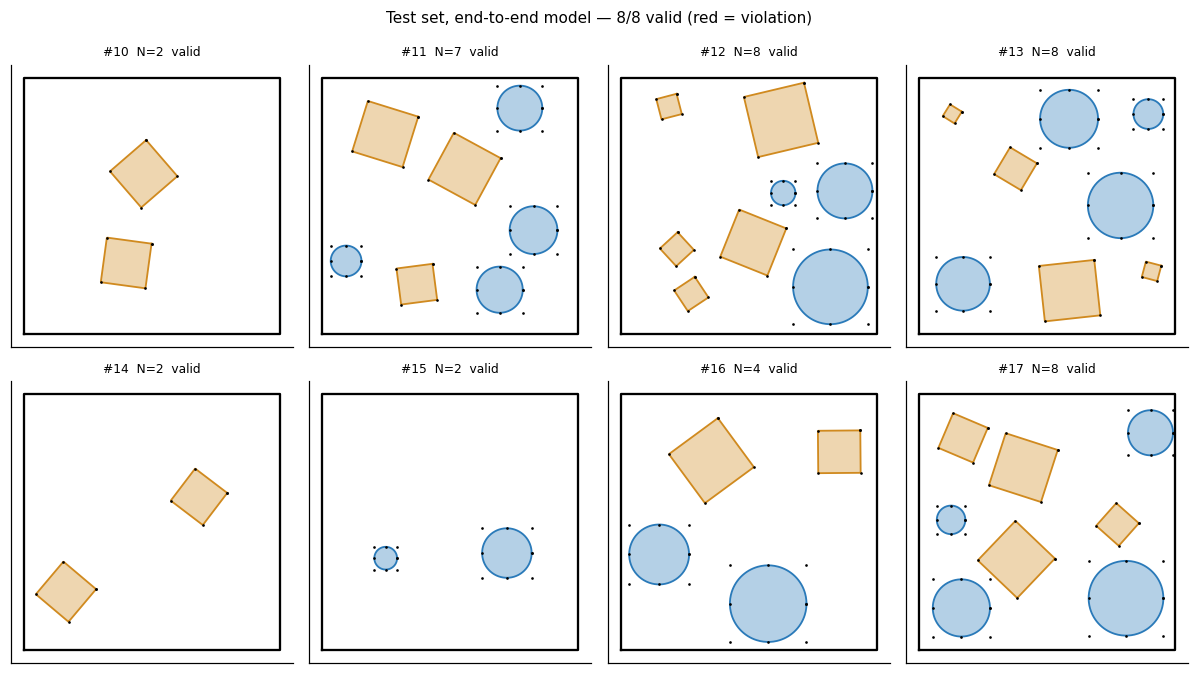

In [7]:
sample_and_plot("test", list(range(10, 18)), "Test set, end-to-end model")

### 5b. Out-of-distribution examples (9–12 objects, never seen in training)

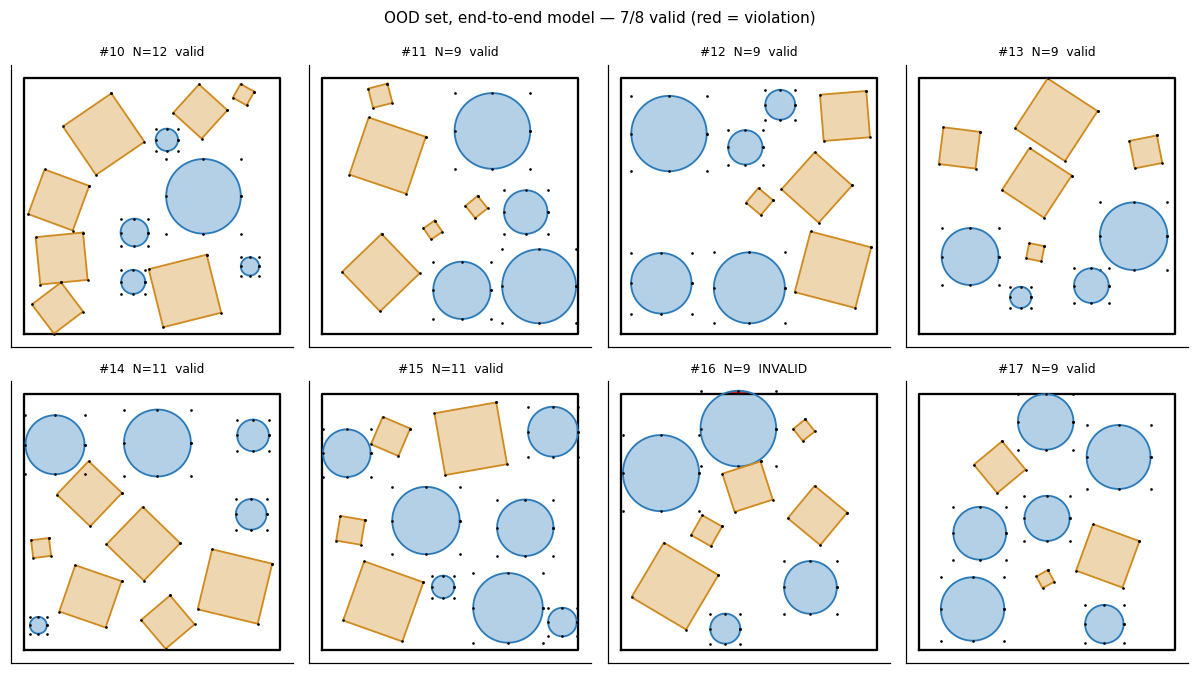

In [8]:
sample_and_plot("test_ood", list(range(10, 18)), "OOD set, end-to-end model")

### 5c. An example with errors

The cell below samples 200 OOD layouts and counts the failures by type. It then shows a **typical overlap failure**: exactly one overlapping pair and nothing else wrong, with the median overlap size among such cases. The layout is shown in full and zoomed in on the faulty region.

75/200 OOD layouts invalid; 30 with an overlap, 45 only crossing a wall
OOD layout #154, N=12:
  • objects #3 (square) and #9 (circle) overlap by area 1.56e-04 (0.4% of the smaller one)


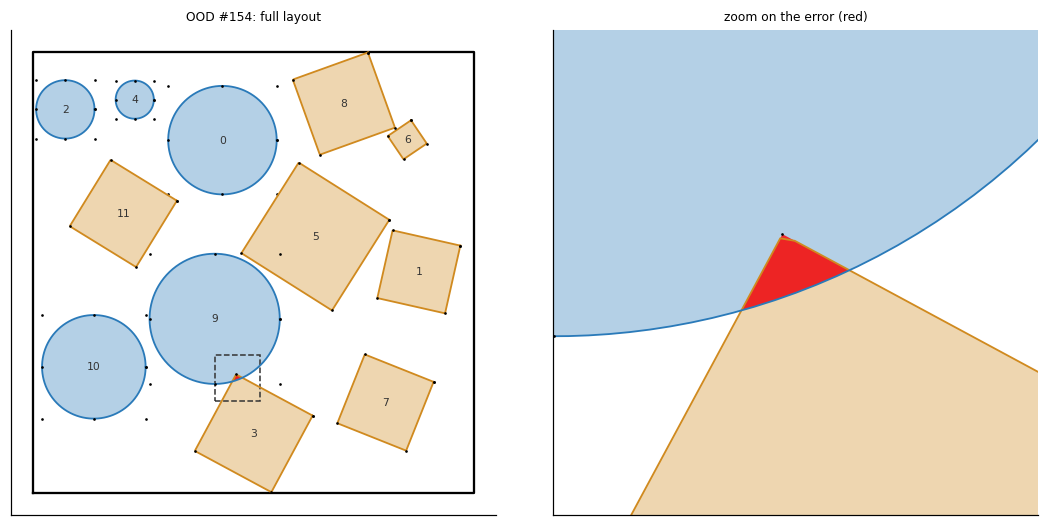

In [9]:
ds = splits["test_ood"]
idx = list(range(0, 200))
b = {k: v.to(DEV) for k, v in collate([ds[i] for i in idx]).items()}
g = torch.Generator(device=DEV).manual_seed(0)
P = diff.sample(model, b["types"], b["sizes"], b["mask"], steps=50, guidance=0.0, generator=g).cpu().numpy()

fails = []
for k, i in enumerate(idx):
    lay = unpack(ds, i, P[k])
    v = layout_violations(*lay)
    if not v["valid"]:
        fails.append((v["overlap_pairs"] > 0, v["overlap_area"] + v["oob_area"], i, lay, v))
n_ovl = sum(f[0] for f in fails)
print(f"{len(fails)}/{len(idx)} OOD layouts invalid; {n_ovl} with an overlap, {len(fails) - n_ovl} only crossing a wall")

# typical case: a single overlapping pair, no wall crossing, median overlap area
single = sorted([f for f in fails if f[4]["overlap_pairs"] == 1 and f[4]["oob_area"] <= 1e-6], key=lambda f: f[1])
has_ovl, _, i, lay, v = single[len(single) // 2] if single else max(fails, key=lambda f: (f[0], f[1]))
types, sizes, poses = lay
geoms = [to_shapely(t, s, *p) for t, s, p in zip(types, sizes, poses)]

problems, boxes = [], []
for a in range(len(geoms)):
    for c in range(a + 1, len(geoms)):
        inter = geoms[a].intersection(geoms[c])
        if inter.area > 1e-6:
            problems.append(f"objects #{a} ({TYPE_NAMES[int(types[a])]}) and #{c} ({TYPE_NAMES[int(types[c])]}) overlap by area {inter.area:.2e} ({inter.area / min(geoms[a].area, geoms[c].area):.1%} of the smaller one)")
            boxes.append(inter.bounds)
    x0, y0, x1, y1 = geoms[a].bounds
    out = max(0, -x0, -y0, x1 - 1, y1 - 1)
    if out > 1e-6:
        problems.append(f"object #{a} ({TYPE_NAMES[int(types[a])]}) pokes {out:.4f} outside the room")
        boxes.append(geoms[a].bounds)
print(f"OOD layout #{i}, N={len(types)}:")
for p in problems:
    print("  •", p)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.8))
plot_layout(a1, types, sizes, poses, title=f"OOD #{i}: full layout")
for k, (t, p) in enumerate(zip(types, poses)):
    a1.text(p[0], p[1], str(k), ha="center", va="center", fontsize=7, color="#333")
bx = np.array(boxes)
cx, cy = (bx[:, 0].min() + bx[:, 2].max()) / 2, (bx[:, 1].min() + bx[:, 3].max()) / 2
half = max(bx[:, 2].max() - bx[:, 0].min(), bx[:, 3].max() - bx[:, 1].min()) / 2 + 0.04
plot_layout(a2, types, sizes, poses, title="zoom on the error (red)")
a2.set_xlim(cx - half, cx + half); a2.set_ylim(cy - half, cy + half)
a1.add_patch(plt.Rectangle((cx - half, cy - half), 2 * half, 2 * half, fill=False, ls="--", lw=1, color="#333"))
plt.tight_layout(); plt.show()

What the failures look like:
- The remaining errors are **small**: a thin overlap where two objects graze each other, or an object sticking slightly through a wall (the median protrusion is ≈ 0.5% of the room width).
- With the overlap loss, most failures are now **wall** failures rather than overlaps. The penalty pushes objects apart and therefore slightly outward.
- The full pipeline (adding guidance and refinement) fixes these and reaches 100% (test) and 100% (OOD). The aim here was to see how far the network gets **on its own**.

## 6. Summary

| | without overlap loss | **with overlap loss (λ = 1)** |
|---|---|---|
| valid, test (N = 2–8) | 75.8% | **93.6%** |
| valid, OOD (N = 9–12) | 17.5% | **60.9%** |
| layouts failing from overlaps (test) | 22.5% | 1.5% |
| diversity (test) | 0.433 | 0.454 |
| best val fit loss | 0.288 | 0.293 |

- Training with the overlap penalty moves most of the constraint handling **into the network**, at almost no cost to denoising quality or variety.
- What remains is mainly small wall crossings and weaker generalisation to many more objects than seen in training.

Possible next steps:
- give the wall term its own, stronger weight;
- add a cheap final step that slides objects back inside the room;
- train with more objects per layout.